In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator, NullFormatter


from delayscan import TRclasses as tr
from delayscan.TRclasses import reduceBins

In [2]:
# Load default mpl style
plt.style.use("assets/TRPES.mplstyle")

#Other standard figure widths
fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

#Dedault mpl colour tablet
colors = list(mcolors.TABLEAU_COLORS)

### Calibration data

In [3]:
# Instrument function parameters
# N0 * exp((-x)/l) + 1
IFparams = np.array([-6.90359945,  0.02964122])

# Low eKE cutoff at eKE = 0.126
IFcutoff = 0.126

In [4]:
# TOF to eKE calibration
# Flight tube length (m), time offset (ns), energy offset (eV)
calParams = np.array([  0.62209127, 48.29925437,  1.10221363])

### Data info

In [5]:
#Streaming potentials
SP_250618c = np.array([0.037811958986494684,  0.12997911802896056 ])
SP_250618d = np.array([-0.004002254614469857,  0.20421880748289375 ])



In [6]:
resultsPath = r"data/"

# Data is organised like this (as we do at UCL)
# rf"{date}/{date}{fileIndex}/{date}{fileIndex}/"


In [7]:
# Here we provide the info to upload and process the data
# In each fileInfo_{date}{index} are the scans from each run
# (i.e., between pumping down and venting)
# I have only used one run but potentially could use more

# resultsFolder,date, fn, pump wl, pulseEnergy pump,probe wl, pulseEnergy probe, integration time, approx time 0, SP before, SP after 
fileInfo_250618b = [
    (resultsPath,"180625","dt", 350.0, 5, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dv", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dx", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # # (resultsPath,"180625","dz", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eb", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ec", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eg", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ei", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ek", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","em", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
]


fileInfos = [fileInfo_250618b,]

In [8]:
allDelays = []
print("Loading files")
for fileInfo in fileInfos:
    scanSet = tr.DelayScanSet()
    for info in fileInfo:

        scan = tr.DelayScan(resultsFolder = info[0],
                            date = info[1],
                            fileIndex = info[2],
                            pumpWavelength = info[3],
                            pumpPulseEnergy = info[4],
                            probeWavelength = info[5],
                            probePulseEnergy = info[6],
                            integrationTime = info[7],
                            timeZero = info[8],
                            SPbefore = info[9],
                            SPafter = info[10],
                            calParams = calParams,
                            IFparams = IFparams,
                            IFcutoff = IFcutoff,
                            )
        scan.importData()
        scan.applyJacobian()
        scan.convert_to_eKE()
        scan.applyInstrumentFunction()
        scan.correctStreamingPotential()
        scan.normaliseByIntegrationTime()
        print(f"{info[1]}{info[2]}")

        scanSet.append(scan)
    allDelays.append(scanSet)
print("Files loaded")

Loading files


180625dt
180625dv
180625dx
Files loaded


### Plot one delay (to determine indices of pp, pump, probe, nothing)

0 96893.1779516877
	 0 96893.1779516877
1 652222.4913167137
	 1 652222.4913167137
2 -8.991004857552307
	 1 652222.4913167137
3 134662.50064479027
	 1 652222.4913167137


1

In [34]:
scan = scanSet[1]
counts = [np.sum(scan.spectra[i::4,1]) for i in range(4)]


np.argsort(counts)


array([2, 0, 3, 1])

0: 71.7043 mm, tot counts: 1830
1: 71.7043 mm, tot counts: 14078
2: 71.7043 mm, tot counts: 0
3: 71.7043 mm, tot counts: 3890


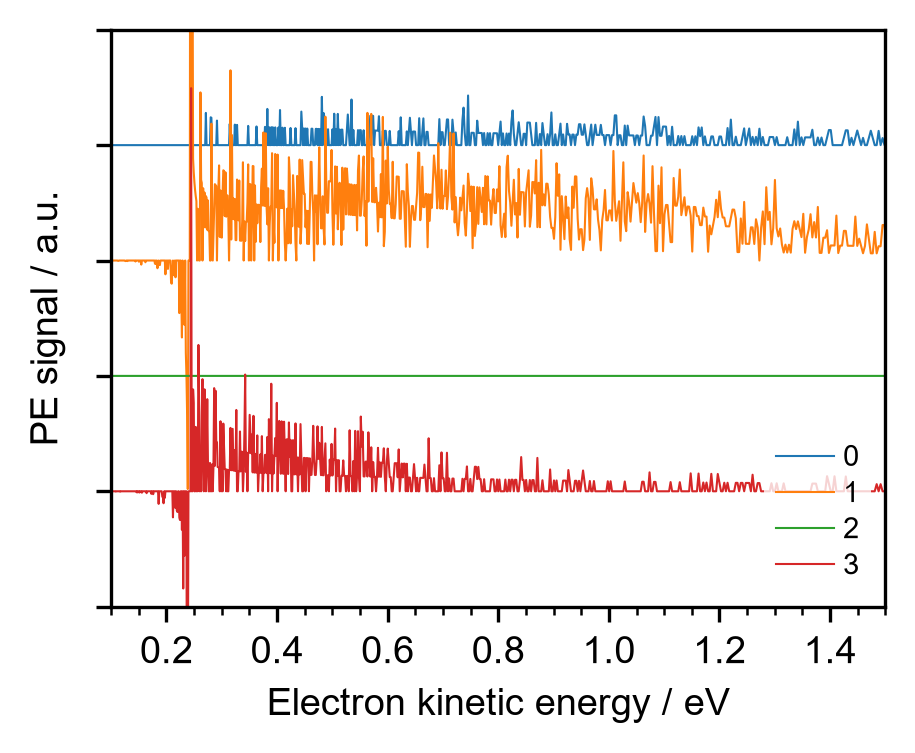

In [24]:
# Select one scan
# It doesn't matter which if they have all been recorded at the same time)
# Otherwise one should do this for each of them
scan = scanSet[1]
# Select one delay (preferably one where the pump-probe signal is strong enough)
# Here ind the index of the time delay
ind= 6 #0 to (len(delays))-1


fig,ax = plt.subplots()
for i,spectrum in enumerate(scan.spectra[ind*4:ind*4+4]): # *4 as there are 4 spectra per delay
    print(f"{i}: {scan.delays[ind]} mm, tot counts: {np.sum(spectrum[1]):.0f}")
    ax.plot(spectrum[0],spectrum[1]-i*50, lw=.5, label=f"{i}")

ax.set_xlim(0.1,1.5)
ax.set_ylim(-200,50)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("PE signal / a.u.")
ax.set_yticklabels([])
ax.xaxis.set_major_locator(MultipleLocator(.2))
ax.xaxis.set_minor_locator(MultipleLocator(.05))

ax.legend(frameon=True,linewidth=0)
plt.show()

### Get subtracted spectra

In [10]:
#Here you subtract pump probe and nothing from pp by using the indices from above
# While the spectra are saved also saved as pps,pumps,probes and nothings
# the only important one is the first index as the others are all subtracted from it
print(scanSet.date)
for scan in scanSet:
    scan.subtract_background(1,3,0,2)

{'180625'}


In [11]:
# plot one scan to check subtraction was successsful
scan = scanSet[0]
subtracted_rebinned = []
rebins = 10

for spectrum in scan.subtracted:
    spectrum = spectrum[:,np.logical_and(spectrum[0]>=.3,spectrum[0]<=5)]
    rebinned_spectrum = reduceBins(spectrum,rebins)
    subtracted_rebinned.append(rebinned_spectrum)
subtracted_rebinned = np.array(subtracted_rebinned)


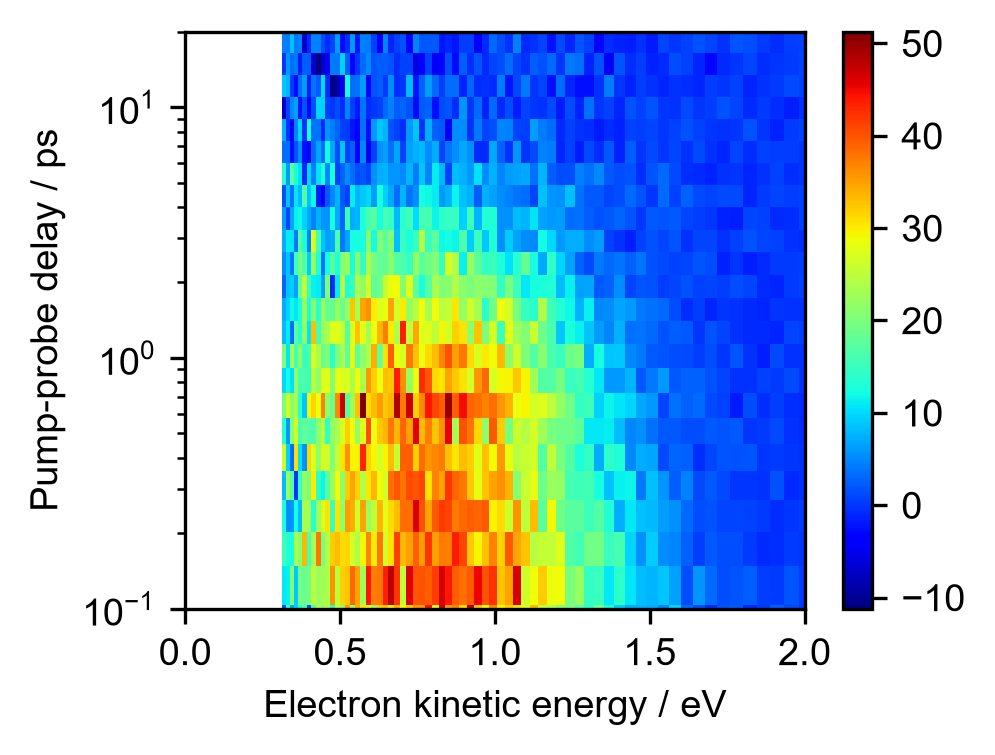

In [12]:
fig,ax = plt.subplots()
im0 = ax.pcolormesh(subtracted_rebinned[0,0],
                    scan.delayTimes,
                    subtracted_rebinned[:,1],
                    cmap='jet',
                    # shading='gouraud',
                   )

ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(.1,20)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")
plt.colorbar(im0)

### Add scanSets from same day

1. Remove data points below eKE cutoff and above 5 eV
2. Sum intensities for the same eKE and time delay (this can only be done if you didn't change the time points at any point & are using the same SP measurements)
3. Rebin data if you like

There is some confusion in the naming when it comes to summed and subtracted

In [13]:

# 1. Remove data points below low eKE cutoff and above 5 eV
for scan in scanSet:
    print(f"Min eKE: {scan.IFcutoff+scan.streamingPotentialCorrection:.4f} eV")
    scan.trim_energies()



Min eKE: 0.3100 eV
Min eKE: 0.3100 eV
Min eKE: 0.3100 eV


In [14]:
# 2. Sum intensities for the same eKE and time delay (this can only be done if you didn't change the time points at any point & are using the same SP measurements)

scanSet.add_scans()


    

In [15]:
# 3. Rebin data if you like

rebins = 10
scanSet.rebin_subtracted_spectra(rebins)

### Plot heatmap of subtracted_rebinned

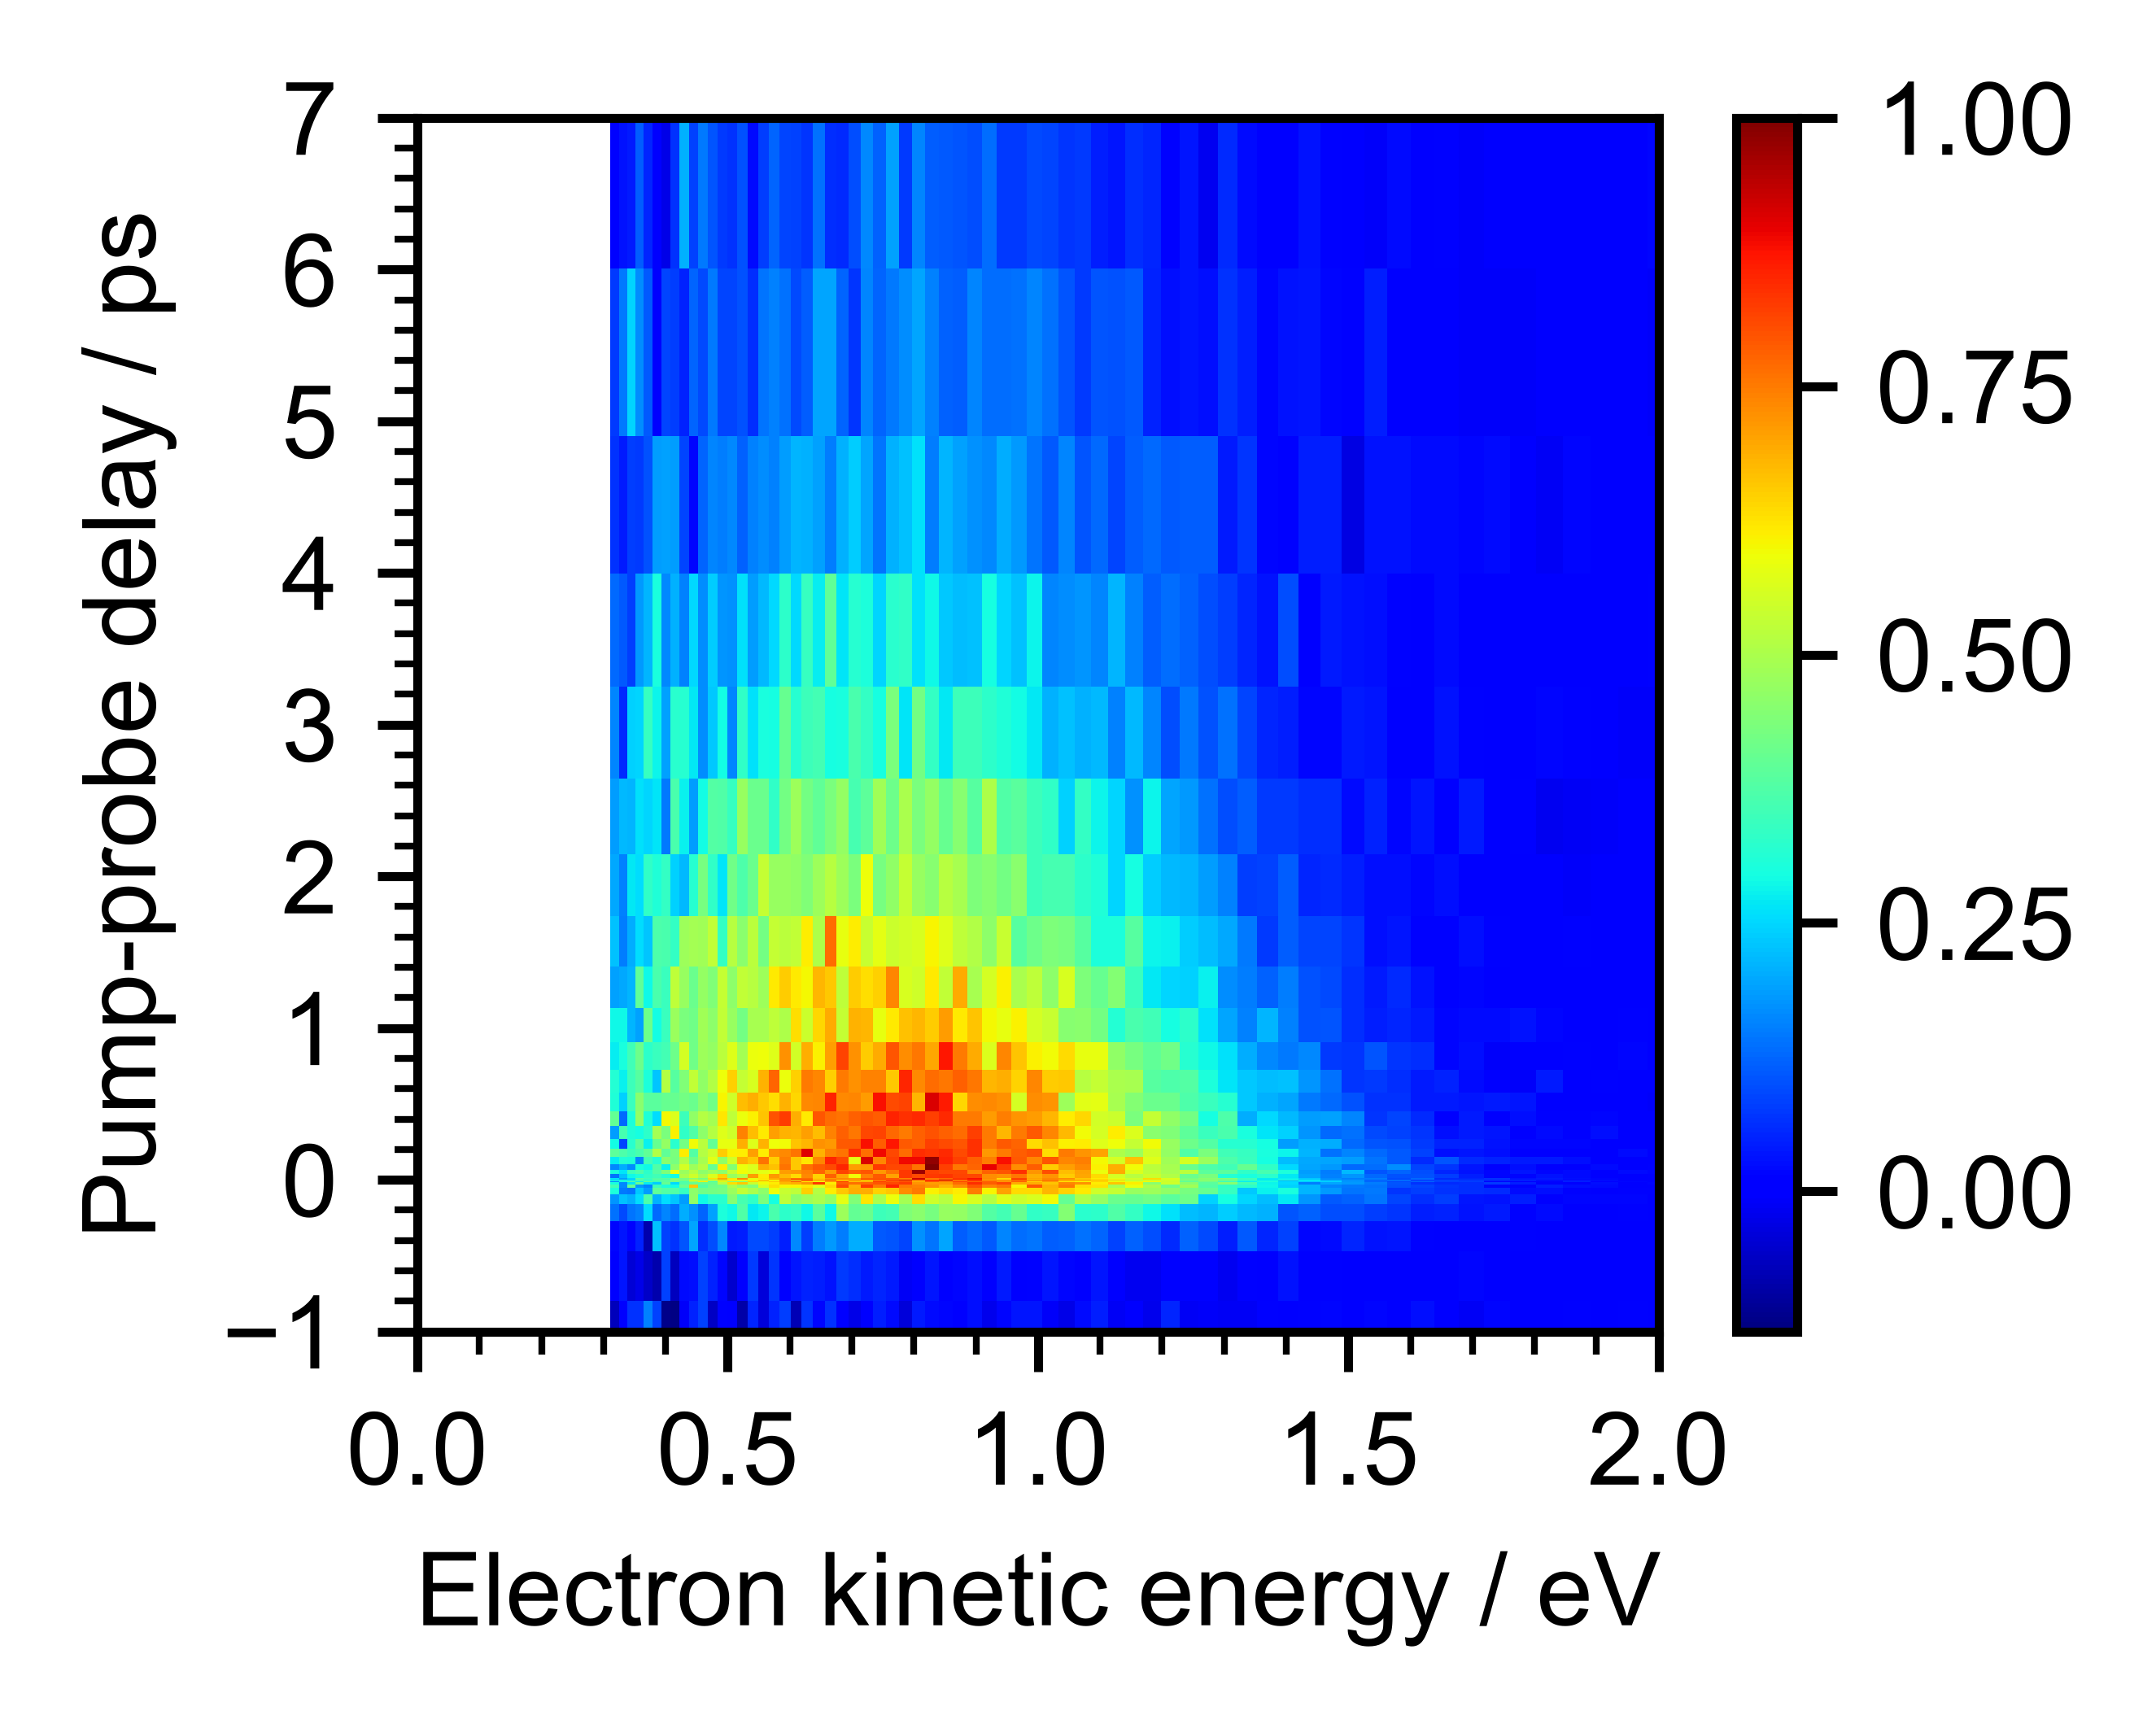

In [16]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-1,7)
# ax.set_yscale('log')
# ax.set_ylim(0.01,10)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

In [17]:
scanSet.save_subtracted()
scanSet.save_rebinned()